In [1]:
%matplotlib inline
%config InlineBackend.print_figure_kwargs = {"bbox_inches": None}
%config InlineBackend.figure_formats = ["retina"]
import json

import matplotlib.pyplot as plt
import tol_colors as tc
from paper import fit_height, mark_value, smooth, darken  # importing paper registers the bundled Inter font
plt.style.use("paper.mplstyle")

cset = tc.colorsets["bright"]
with open("../dapo.json") as f:
    data = json.load(f)

## fig1

**Figure 1: AIME 2024 scores of DAPO on the Qwen2.5-32B base model over training.** The grey dashed line marks DeepSeek-R1-Zero-Qwen-32B's score of 47, reached after 10k steps; the blue dashed line marks DAPO's final avg@32. DAPO reaches 49.6 avg@32 after 5.3k steps, surpassing DeepSeek-R1-Zero-Qwen-32B with about 50% of its training steps.

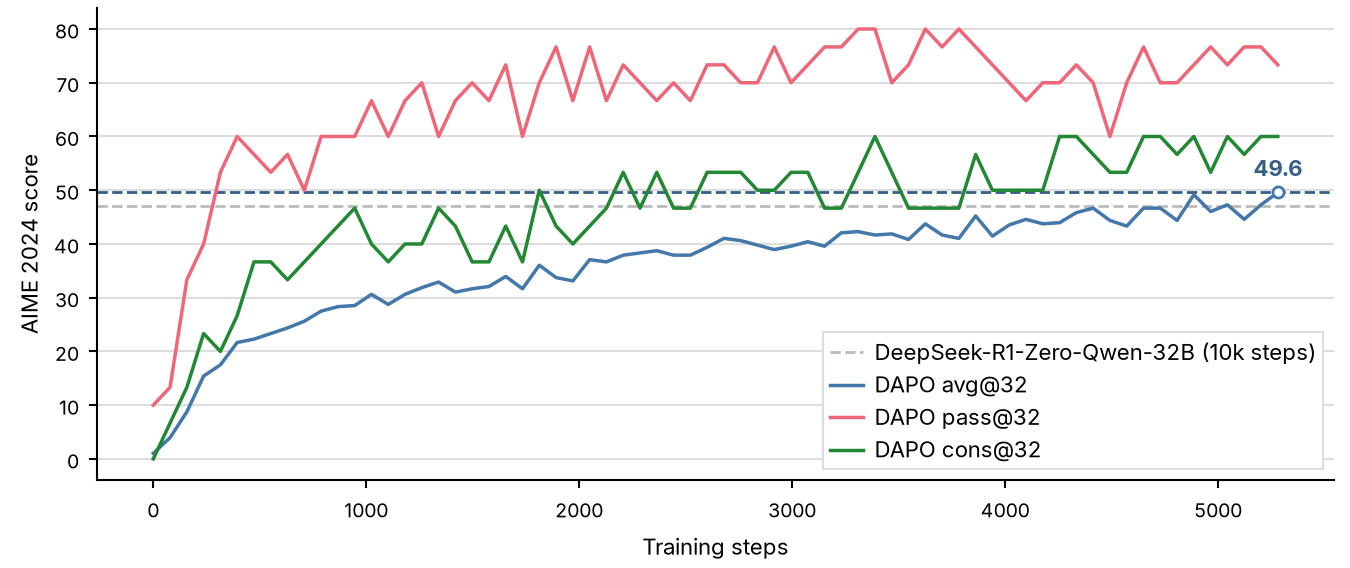

In [2]:
curves = data["fig1"]
fig, ax = plt.subplots(figsize=(6.75, 2))
ax.axhline(47, linestyle="--", linewidth=1, color=cset.grey, zorder=1, label="DeepSeek-R1-Zero-Qwen-32B (10k steps)")
for name, color in zip(["DAPO avg@32", "DAPO pass@32", "DAPO cons@32"], [cset.blue, cset.red, cset.green]):
    ax.plot(curves[name]["step"], curves[name]["value"], color=color, label=name)
avg = curves["DAPO avg@32"]
mark_value(ax, avg["step"][-1], avg["value"][-1], f"{avg['value'][-1]:.1f}", cset.blue)
ax.set_xlabel("Training steps")
ax.set_ylabel("AIME 2024 score")
ax.legend(loc="lower right")
fit_height(fig, ax, aspect=0.382)
fig.savefig("fig1.pdf")
fig.savefig("fig1.png")
plt.show()

## fig2

**Figure 2: Accuracy on AIME and entropy of the actor model's generation probabilities, with and without Clip-Higher.** Dashed lines in (a) mark each run's best avg@32; (b) is smoothed with a moving average over 5% of the steps; faint lines show raw values. Clip-Higher keeps entropy from collapsing and raises the best AIME avg@32 from 0.269 to 0.406.

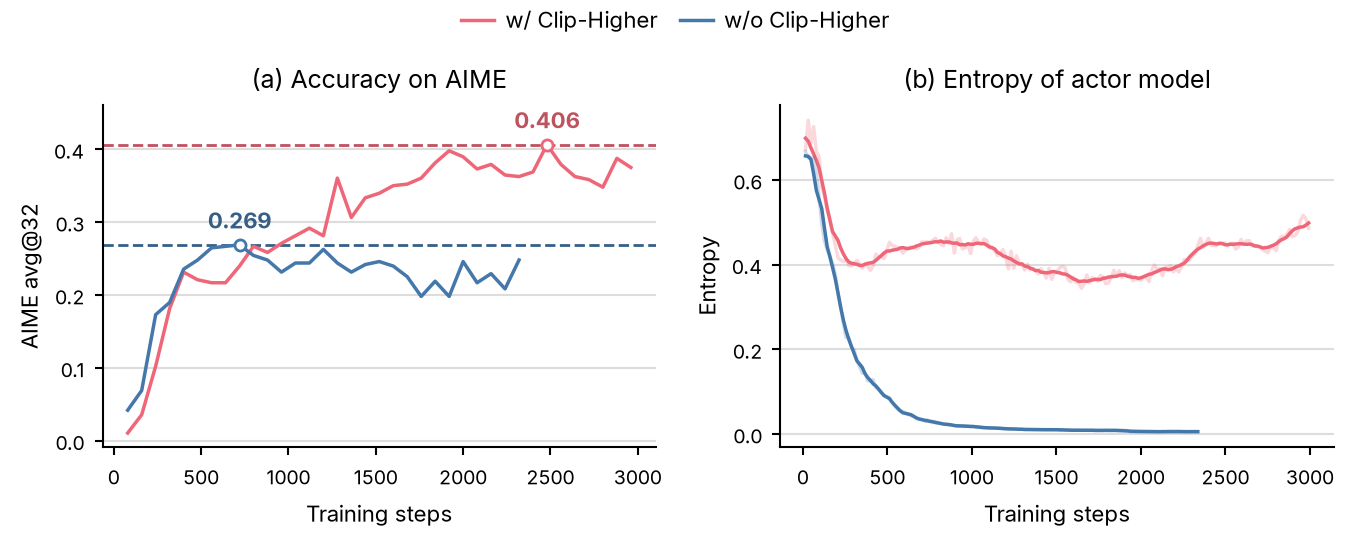

In [3]:
series = {"w/ Clip-Higher": cset.red, "w/o Clip-Higher": cset.blue}
fig, (ax_acc, ax_ent) = plt.subplots(1, 2, figsize=(6.75, 2))
for name, color in series.items():
    acc = data["fig2a"][name]
    ax_acc.plot(acc["step"], acc["value"], color=color, label=name)
    best = max(range(len(acc["value"])), key=acc["value"].__getitem__)
    mark_value(ax_acc, acc["step"][best], acc["value"][best], f"{acc['value'][best]:.3f}", color)
    ent = data["fig2b"][name]
    ax_ent.plot(ent["step"], ent["value"], color=color, alpha=0.25)
    ax_ent.plot(ent["step"], smooth(ent["value"]), color=color)
ax_acc.set(title="(a) Accuracy on AIME", xlabel="Training steps", ylabel="AIME avg@32")
ax_ent.set(title="(b) Entropy of actor model", xlabel="Training steps", ylabel="Entropy")
fig.legend(loc="outside upper center", ncol=len(series), frameon=False, borderaxespad=0)
fit_height(fig, [ax_acc, ax_ent], aspect=0.618)
fig.savefig("fig2.pdf")
fig.savefig("fig2.png")
plt.show()

## fig3

**Figure 3: Mean up-clipped probability and proportion of samples with an accuracy of 1 during training.** Both panels are smoothed with a moving average over 5% of the steps; faint lines show raw values. Tokens clipped at the upper bound have a mean probability of only about 0.13 after the first few hundred steps, and the share of samples with accuracy 1 grows steadily to about 0.57 by 9k steps.

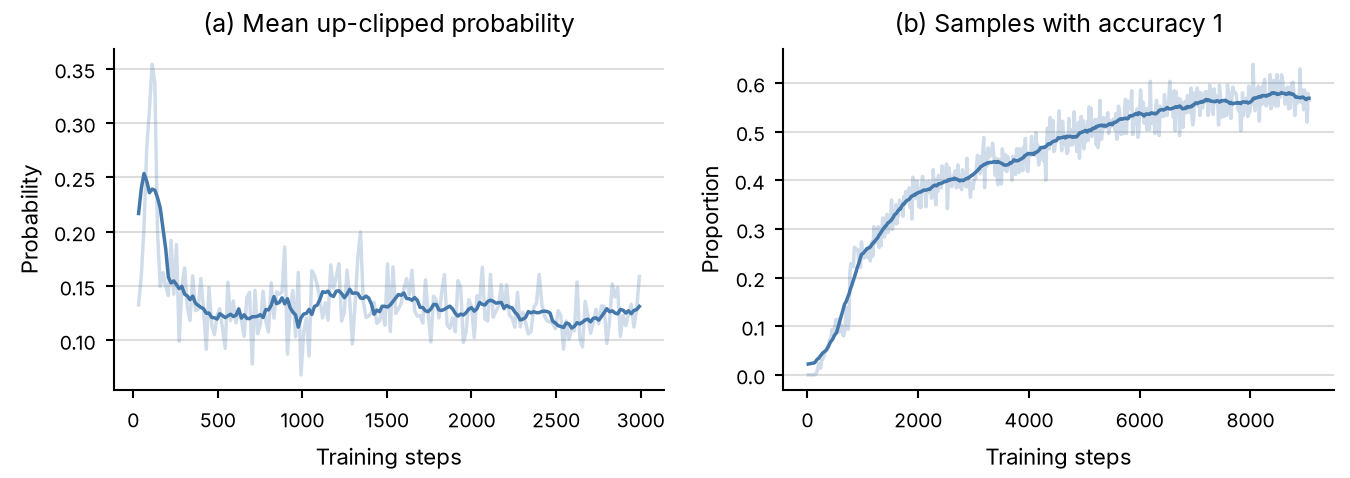

In [4]:
fig, (ax_clip, ax_acc1) = plt.subplots(1, 2, figsize=(6.75, 2))
for ax, key in [(ax_clip, "fig3a"), (ax_acc1, "fig3b")]:
    curve = data[key]
    ax.plot(curve["step"], curve["value"], color=cset.blue, alpha=0.25)
    ax.plot(curve["step"], smooth(curve["value"]), color=cset.blue)
ax_clip.set(title="(a) Mean up-clipped probability", xlabel="Training steps", ylabel="Probability")
ax_acc1.set(title="(b) Samples with accuracy 1", xlabel="Training steps", ylabel="Proportion")
fit_height(fig, [ax_clip, ax_acc1], aspect=0.618)
fig.savefig("fig3.pdf")
fig.savefig("fig3.png")
plt.show()

## fig4

**Figure 4: Entropy of generation probabilities and average response length, with and without token-level policy gradient loss.** Both panels are smoothed with a moving average over 5% of the steps; faint lines show raw values. Without token-level loss, entropy climbs to about 3 and response length surges past 4k tokens before collapsing, while with it entropy stays below 1 and length grows steadily.

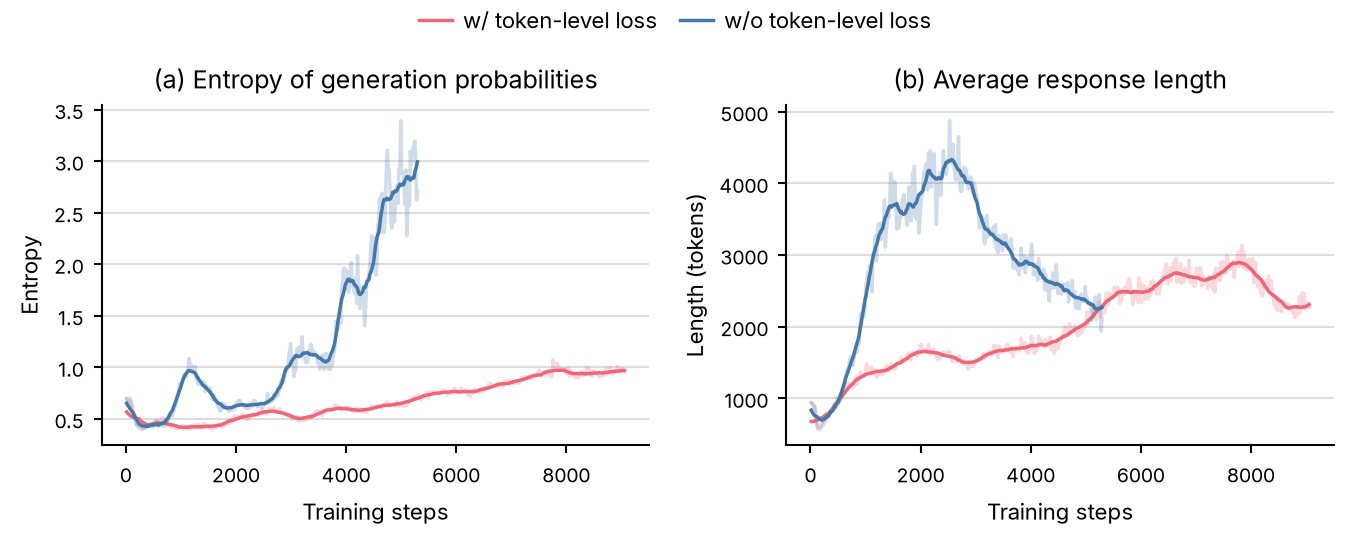

In [5]:
series = {"w/ token-level loss": cset.red, "w/o token-level loss": cset.blue}
fig, (ax_ent, ax_len) = plt.subplots(1, 2, figsize=(6.75, 2), sharex=True)
for name, color in series.items():
    for ax, key in [(ax_ent, "fig4a"), (ax_len, "fig4b")]:
        curve = data[key][name]
        ax.plot(curve["step"], curve["value"], color=color, alpha=0.25)
        ax.plot(curve["step"], smooth(curve["value"]), color=color, label=name if ax is ax_ent else None)
ax_ent.set(title="(a) Entropy of generation probabilities", xlabel="Training steps", ylabel="Entropy")
ax_len.set(title="(b) Average response length", xlabel="Training steps", ylabel="Length (tokens)")
fig.legend(loc="outside upper center", ncol=len(series), frameon=False, borderaxespad=0)
fit_height(fig, [ax_ent, ax_len], aspect=0.618)
fig.savefig("fig4.pdf")
fig.savefig("fig4.png")
plt.show()

## fig5

**Figure 5: Performance on AIME and entropy of the actor model, with and without overlong filtering.** Dashed lines in (a) mark each run's best avg@32; (b) is smoothed with a moving average over 5% of the steps; faint lines show raw values. Overlong filtering stabilizes entropy and raises the best AIME avg@32 from 0.302 to 0.358.

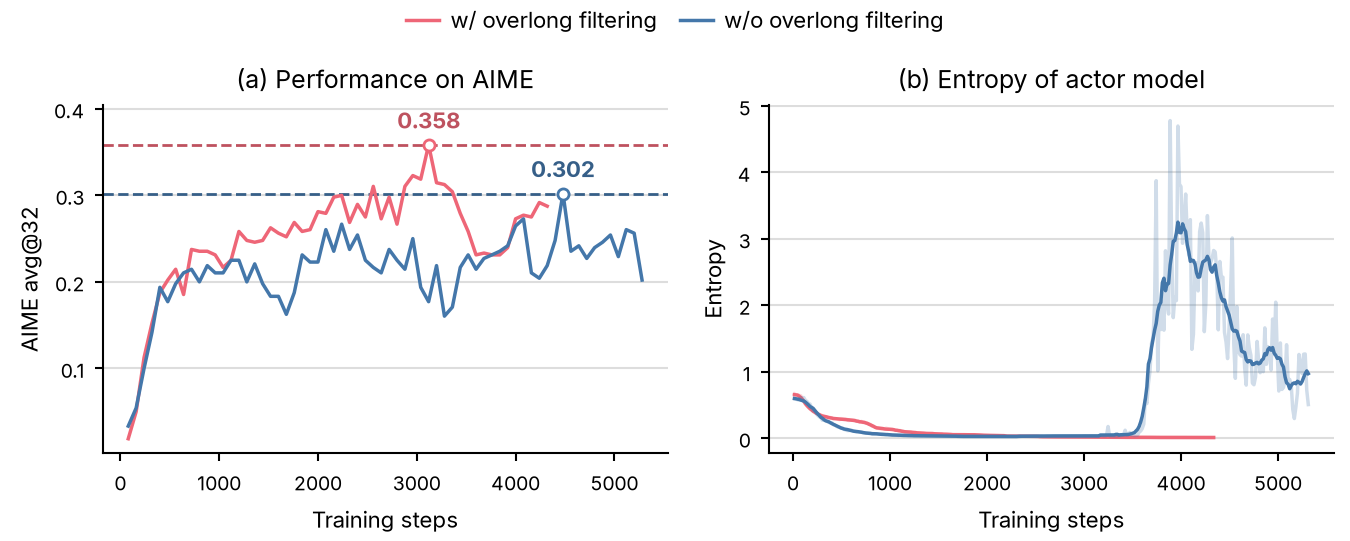

In [6]:
series = {"w/ overlong filtering": cset.red, "w/o overlong filtering": cset.blue}
fig, (ax_acc, ax_ent) = plt.subplots(1, 2, figsize=(6.75, 2))
for name, color in series.items():
    acc = data["fig5a"][name]
    ax_acc.plot(acc["step"], acc["value"], color=color, label=name)
    best = max(range(len(acc["value"])), key=acc["value"].__getitem__)
    mark_value(ax_acc, acc["step"][best], acc["value"][best], f"{acc['value'][best]:.3f}", color)
    ent = data["fig5b"][name]
    ax_ent.plot(ent["step"], ent["value"], color=color, alpha=0.25)
    ax_ent.plot(ent["step"], smooth(ent["value"]), color=color)
ax_acc.set(title="(a) Performance on AIME", xlabel="Training steps", ylabel="AIME avg@32")
ax_ent.set(title="(b) Entropy of actor model", xlabel="Training steps", ylabel="Entropy")
fig.legend(loc="outside upper center", ncol=len(series), frameon=False, borderaxespad=0)
fit_height(fig, [ax_acc, ax_ent], aspect=0.618)
fig.savefig("fig5.pdf")
fig.savefig("fig5.png")
plt.show()

## fig6

**Figure 6: AIME avg@32 over training before and after applying dynamic sampling on a baseline setting.** Dashed lines mark each run's best avg@32. With dynamic sampling the run peaks at 0.438 after 2.3k steps, above the 0.421 the run without it needs 6.1k steps to reach.

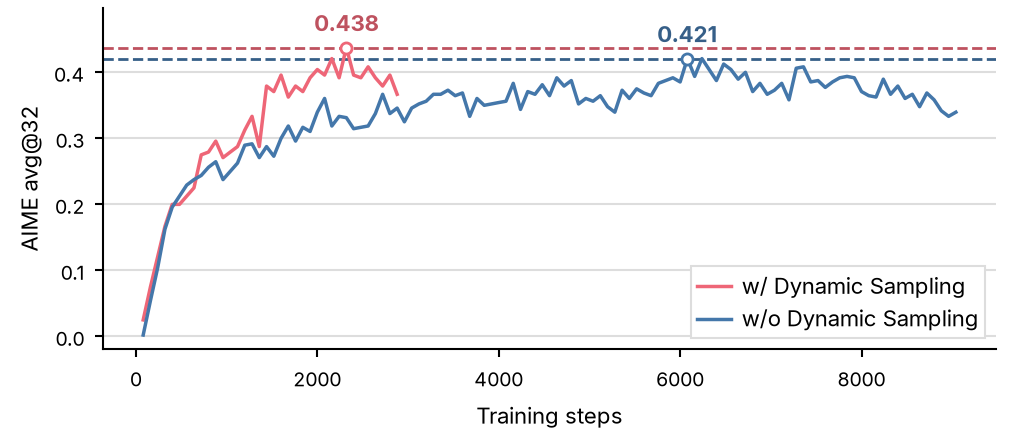

In [7]:
series = {"w/ Dynamic Sampling": cset.red, "w/o Dynamic Sampling": cset.blue}
fig, ax = plt.subplots(figsize=(5.0625, 2))
for name, color in series.items():
    acc = data["fig6"][name]
    ax.plot(acc["step"], acc["value"], color=color, label=name)
    best = max(range(len(acc["value"])), key=acc["value"].__getitem__)
    mark_value(ax, acc["step"][best], acc["value"][best], f"{acc['value'][best]:.3f}", color)
ax.set_xlabel("Training steps")
ax.set_ylabel("AIME avg@32")
ax.legend(loc="lower right")
fit_height(fig, ax, aspect=0.382)
fig.savefig("fig6.pdf")
fig.savefig("fig6.png")
plt.show()

## fig7

**Figure 7: Training dynamics of DAPO.** All panels are smoothed with a moving average over 5% of the steps; faint lines show raw values. Over 5.3k steps the mean response length grows from about 0.6k to 4.5k tokens and the reward score rises from −0.85 to 0.35, while generation entropy and mean probability stay in a narrow band.

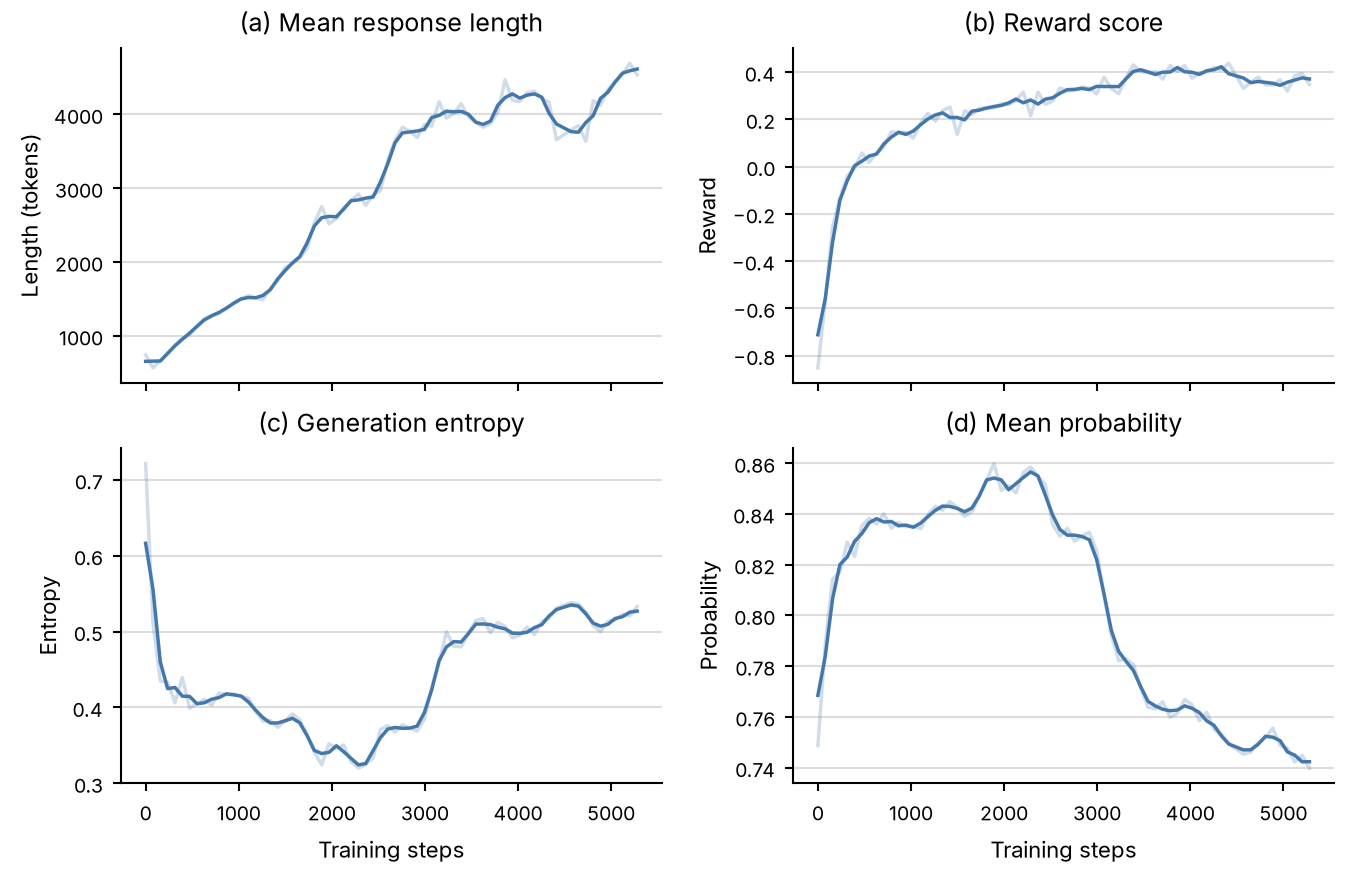

In [8]:
panels = [("fig7a", "(a) Mean response length", "Length (tokens)"),
          ("fig7b", "(b) Reward score", "Reward"),
          ("fig7c", "(c) Generation entropy", "Entropy"),
          ("fig7d", "(d) Mean probability", "Probability")]
fig, axes = plt.subplots(2, 2, figsize=(6.75, 3), sharex=True)
for ax, (key, title, ylabel) in zip(axes.flat, panels):
    curve = data[key]
    ax.plot(curve["step"], curve["value"], color=cset.blue, alpha=0.25)
    ax.plot(curve["step"], smooth(curve["value"]), color=cset.blue)
    ax.set(title=title, ylabel=ylabel)
for ax in axes[1]:
    ax.set_xlabel("Training steps")
fit_height(fig, axes, aspect=0.618)
fig.savefig("fig7.pdf")
fig.savefig("fig7.png")
plt.show()